# 02 · CO1: Text extraction, preprocessing, cleaning & vectorisation (7 marks)
1. **Extraction** of questions from unstructured documents (PDF / DOCX / TXT / images via OCR)
2. **Cleaning**: HTML, LaTeX, marks, numbering, unicode, diagram code
3. **Preprocessing**: tokenisation, stop-words, POS tagging, stemming vs lemmatisation
4. **Vectorisation**: BoW, TF-IDF (word & char n-grams), Word2Vec, linguistic feature vectors

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option('display.max_colwidth', 120)
REPORTS = ROOT / 'reports'; FIG = REPORTS / 'figures'
def show(name): display(Image(filename=str(FIG / name)))
def rj(name): return json.loads((REPORTS / name).read_text())

## 1 · Text extraction from an unstructured question paper

In [2]:
from src.data.extract import read_text, extract_questions
raw = read_text(ROOT/'samples/sample_question_paper.txt')
print(raw[:700])

XYZ PUBLIC SCHOOL - ANNUAL EXAMINATION
Time: 3 hours                                   Maximum Marks: 80
General Instructions: All questions are compulsory.

Section A
Q1. What is the SI unit of force? [1 mark]
Q2. Name the gas released during photosynthesis. [1 mark]
Q3. Which of the following is a prime number?
A) 21
B) 27
C) 29
D) 33
Section B
Q4. Explain why we see lightning before we hear thunder. [3 marks]
Q5. A car accelerates uniformly from 10 m/s to 30 m/s in 5 seconds. Calculate its acceleration and the distance travelled. [3 marks]
Q6. Describe the role of enzymes in digestion. [3 marks]
Section C
Q7. Prove that the sum of the angles of a triangle is 180 degrees. [5 marks]
Q8. Eva


In [3]:
qs = extract_questions(ROOT/'samples/sample_question_paper.txt')
print(f'{len(qs)} questions extracted (headers, MCQ options and marks removed, sub-questions split):')
for i,q in enumerate(qs,1): print(f'{i:2d}.', q)

11 questions extracted (headers, MCQ options and marks removed, sub-questions split):
 1. What is the SI unit of force?
 2. Name the gas released during photosynthesis.
 3. Which of the following is a prime number?
 4. Explain why we see lightning before we hear thunder.
 5. A car accelerates uniformly from 10 m/s to 30 m/s in 5 seconds. Calculate its acceleration and the distance travelled.
 6. Describe the role of enzymes in digestion.
 7. Prove that the sum of the angles of a triangle is 180 degrees.
 8. Evaluate the impact of the Green Revolution on Indian agriculture, considering both economic and environmental consequences.
 9. Derive the expression for the escape velocity of a body from the surface of the Earth.
10. Find all real values of k for which the equation x^2 + kx + 4 = 0 has two distinct real roots.
11. सिद्ध कीजिए कि 2 का वर्गमूल एक अपरिमेय संख्या है।


In [4]:
# the same works on DOCX and PDF files
qs_docx = extract_questions(ROOT/'samples/sample_question_paper.docx')
print(len(qs_docx), 'questions from DOCX')

11 questions from DOCX


## 2 · Cleaning noisy text

In [5]:
from src.nlp.cleaning import clean_text
noisy = ['Q3. Find the value of $\\frac{x^2}{4}$ when $x = 6$ <b>[2 marks]</b>',
         '(a) Compute $\\sqrt{45} - 2\\sqrt{5}$. [asy] draw((0,0)--(1,1)); [/asy]',
         'Which of the following   is NOT a ___ gas?&nbsp;',
         '1) If $a \\le b$ and $b \\neq 0$, find $\\dfrac{a}{b}$.']
pd.DataFrame({'raw': noisy, 'cleaned': [clean_text(t) for t in noisy]})

,raw,cleaned
0,Q3. Find the value of $\frac{x^2}{4}$ when $x = 6$ <b>[2 marks]</b>,Find the value of (x^2)/(4) when x = 6
1,"(a) Compute $\sqrt{45} - 2\sqrt{5}$. [asy] draw((0,0)--(1,1)); [/asy]",Compute sqrt 45 - 2 sqrt 5 . [diagram]
2,Which of the following is NOT a ___ gas?&nbsp;,Which of the following is NOT a ___ gas?
3,"1) If $a \le b$ and $b \neq 0$, find $\dfrac{a}{b}$.","If a <= b and b != 0 , find (a)/(b) ."


## 3 · Preprocessing pipeline step by step

In [6]:
from src.nlp.cleaning import preprocess_steps
s = preprocess_steps('Q5. The students were running experiments to determine how quickly the enzymes break down proteins.')
for k,v in s.items(): print(f'{k:18s}', v)

raw                Q5. The students were running experiments to determine how quickly the enzymes break down proteins.
cleaned            The students were running experiments to determine how quickly the enzymes break down proteins.
tokens             ['the', 'students', 'were', 'running', 'experiments', 'to', 'determine', 'how', 'quickly', 'the', 'enzymes', 'break', 'down', 'proteins']
pos_tags           [('the', 'DT'), ('students', 'NNS'), ('were', 'VBD'), ('running', 'VBG'), ('experiments', 'NNS'), ('to', 'TO'), ('determine', 'VB'), ('how', 'WRB'), ('quickly', 'RB'), ('the', 'DT'), ('enzymes', 'NNS'), ('break', 'VBP'), ('down', 'RP'), ('proteins', 'NNS')]
without_stopwords  ['students', 'running', 'experiments', 'determine', 'how', 'quickly', 'enzymes', 'break', 'proteins']
stemmed            ['student', 'run', 'experi', 'determin', 'how', 'quickli', 'enzym', 'break', 'protein']
lemmatized         ['student', 'run', 'experiment', 'determine', 'how', 'quickly', 'enzyme', 'break', 'p

In [7]:
from src.nlp.cleaning import preprocess
words = ['studies','studying','better','running','analysis','analyses','caring','cared']
pd.DataFrame({'word':words,'porter_stem':[preprocess(w,'stem',False)[0] for w in words],
              'wordnet_lemma':[preprocess(w,'lemma',False)[0] for w in words]})

,word,porter_stem,wordnet_lemma
0,studies,studi,study
1,studying,studi,study
2,better,better,better
3,running,run,run
4,analysis,analysi,analysis
5,analyses,analys,analysis
6,caring,care,care
7,cared,care,care


## 4 · Vectorisation

In [8]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
docs = ['What is the capital of France?', 'Prove that the square root of two is irrational.',
        'What is the square of seven?']
for V in (CountVectorizer(), TfidfVectorizer()):
    X = V.fit_transform(docs)
    display(Markdown(f'**{V.__class__.__name__}**'))
    display(pd.DataFrame(X.toarray().round(2), columns=V.get_feature_names_out()))

**CountVectorizer**

,capital,france,irrational,is,of,prove,root,seven,square,that,the,two,what
0,1,1,0,1,1,0,0,0,0,0,1,0,1
1,0,0,1,1,1,1,1,0,1,1,1,1,0
2,0,0,0,1,1,0,0,1,1,0,1,0,1


**TfidfVectorizer**

,capital,france,irrational,is,of,prove,root,seven,square,that,the,two,what
0,0.53,0.53,0.00,0.31,0.31,0.00,0.00,0.00,0.00,0.00,0.31,0.00,0.40
1,0.00,0.00,0.39,0.23,0.23,0.39,0.39,0.00,0.30,0.39,0.23,0.39,0.00
2,0.00,0.00,0.00,0.33,0.33,0.00,0.00,0.56,0.42,0.00,0.33,0.00,0.42


In [9]:
from gensim.models import Word2Vec
w2v = Word2Vec.load(str(ROOT/'models_store/word2vec.model'))
print('Vocabulary:', len(w2v.wv), 'words × 100 dims (trained locally on our questions)')
for w in ['photosynthesis','integer','triangle','passage','force']:
    if w in w2v.wv: print(f'{w:15s} →', [x for x,_ in w2v.wv.most_similar(w, topn=6)])

Vocabulary: 13969 words × 100 dims (trained locally on our questions)
photosynthesis  → ['endothermic', 'chlorophyll', 'biochemical', 'cellular', 'conversion', 'atp']
integer         → ['positive', '389', 'lcm', 'factorial', '454', '4.4']
triangle        → ['abc', 'hypotenuse', 'equilateral', 'isosceles', 'abcd', 'def']
passage         → ['text', 'author', 'infer', 'context', 'writer', 'humankind']
force           → ['gravitational', 'exert', 'torque', 'frictional', 'gravity', 'loosen']


In [10]:
from src.features.linguistic import extract_one, FEATURE_GROUPS
f = extract_one('Evaluate the impact of the Treaty of Versailles on the rise of fascism in Europe.')
pd.DataFrame([(g, k, round(f[k],3)) for g,ks in FEATURE_GROUPS.items() for k in ks], columns=['group','feature','value']).head(30)

,group,feature,value
0,readability,flesch_reading_ease,56.250
1,readability,fk_grade,9.140
2,readability,gunning_fog,11.333
3,readability,smog,11.208
4,readability,coleman_liau,7.747
5,readability,ari,7.108
6,readability,dale_chall,10.697
7,readability,difficult_words,6.000
8,readability,syllables_per_word,1.600
9,lexical,n_chars,81.000


## 5 · Which representation works best? (same Logistic Regression / Ridge, held-out test set)

In [11]:
vc = pd.read_csv(REPORTS/'vectorizer_comparison.csv'); vc

,vectorizer,accuracy,macro_f1,qwk,mae,rmse,spearman,band_accuracy,dims,seconds
0,BoW (counts),0.7059,0.7059,0.7081,13.0260,16.8400,0.6886,0.5674,12048,16.3
1,TF-IDF word 1-2gram,0.7388,0.7374,0.7440,10.0955,13.1938,0.8006,0.6389,40000,32.9
2,TF-IDF word+char,0.7749,0.7742,0.8022,8.9290,11.5746,0.8506,0.6806,100000,119.9
3,Word2Vec (mean),0.6651,0.6577,0.6564,13.1850,16.4486,0.6899,0.5140,100,6.9
4,Linguistic features,0.6880,0.6840,0.6718,13.1487,16.2262,0.7209,0.5149,57,15.3


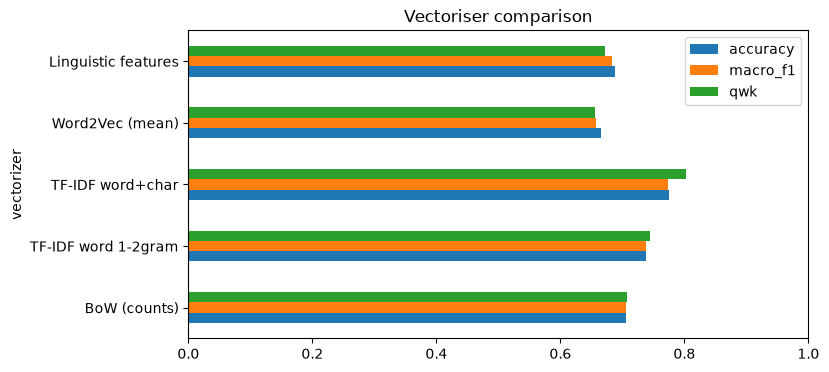

In [12]:
ax = vc.set_index('vectorizer')[['accuracy','macro_f1','qwk']].plot.barh(figsize=(8,4)); ax.set_xlim(0,1); plt.title('Vectoriser comparison'); plt.show()

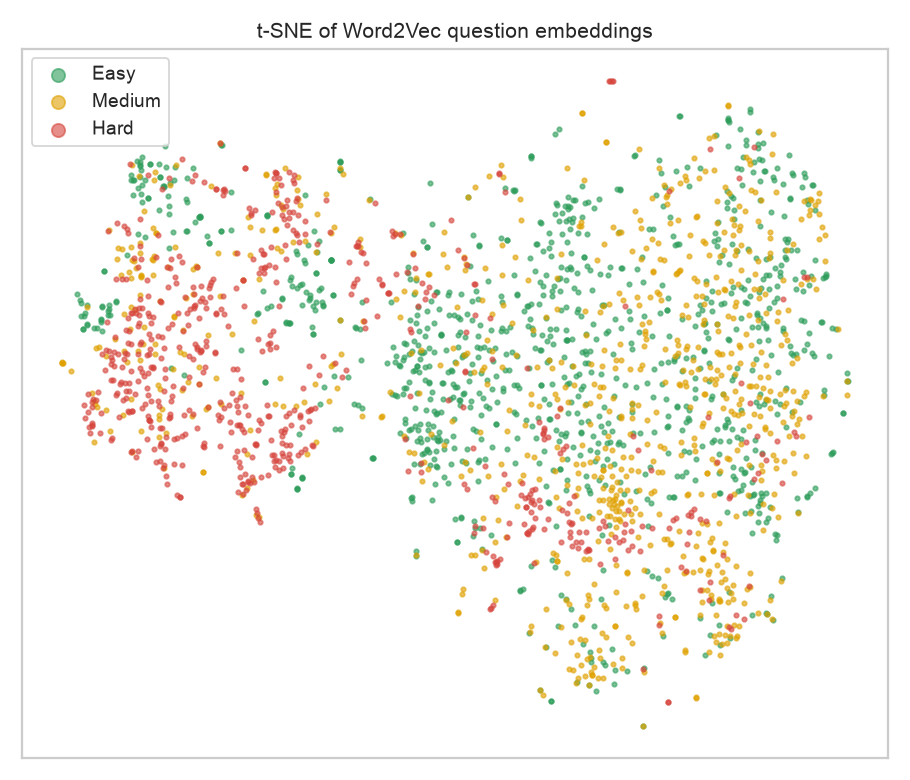

In [13]:
show('embedding_tsne.png')

**Conclusion:** TF-IDF with word + character n-grams is the strongest classic representation
(char n-grams capture maths notation and morphology). Hand-crafted features are weaker alone but
**interpretable** and complementary, so they are combined with TF-IDF in the LightGBM model (notebook 05).